# Minimum-CVaR portfolio allocation with GARCH and Monte Carlo

The objective of this project is to determine an optimal capital allocation across a 5 assets portfolio (AAPL, GLD, JPM, MSFT, XOM) to minimise 1-day Conditional Value at Risk (CVaR). In a preliminary iteration, static historical models failed when extended over a 10-year period because volatility clusters distorted asset correlation structures. Raw historical correlations break down over long periods because high-volatility regimes disproportionately skew co-movements, analogous to a stone dropped in a pond, where ripples temporarily distort the surface, independently of underlying currents.

To resolve this, I used a univariate GARCH(1,1) models with Student’s t innovations to isolate time varying volatility clustering. By dividing raw returns by conditional volatility, I extract standardised residuals that are less affected by volatility regimes. I then build a Pearson correlation matrix from these residuals and apply Cholesky decomposition to generate synchronised, correlated standard normal variables (N(0,1)).

These are mapped to a uniform distribution via the Gaussian Cumulative Distribution Function (CDF) and transformed using the Student's t Percent Point Function (PPF) (parameterised by degrees of freedom ν extracted via GARCH). This captures empirical fat tails that standard normal distributions notoriously underestimate. I note that, as the parameter ν increases toward infinity, the Student's t distribution naturally converges toward a normal distribution.

Using 10 000 000 Monte Carlo scenarios generated through this architecture, I identify the asset weights that minimise 1-day 99% CVaR, with the help of scipy.optimize. To validate the engine, I perform an out-of-sample backtest across the prior 1000 active trading days to ensure our risk forecasts align with real-world tail behaviour.

Finally, important results are pushed to BigQuery, which serves as the backend for a live Data Studio dashboard. This creates a semi-automated data pipeline where weekly notebook re-runs would seamlessly update our risk visualisations.

In [1]:
import pandas as pd
import pydata_google_auth
import yfinance as yf
import bigquery_magics
import matplotlib.pyplot as plt
import numpy as np
from sqlalchemy import create_engine, text
from google.cloud import bigquery
from arch import arch_model
from scipy import stats
from scipy.optimize import minimize

# BigQuery project
project_id = "[project_id]"
credentials = pydata_google_auth.get_user_credentials(scopes=['https://www.googleapis.com/auth/cloud-platform'])
client = bigquery.Client(project=project_id, credentials=credentials)

# allows SQL codes
bigquery_magics.context.credentials = credentials
bigquery_magics.context.project = project_id
%load_ext bigquery_magics

In [ ]:
# downloading stock prices
tickers = ['AAPL', 'MSFT', 'XOM', 'JPM', 'GLD']
df = yf.download(tickers, start='2016-10-27', end='2026-10-27', group_by='ticker')

# reshaping / reformatting
df_stacked = df.stack(level=0, future_stack=True).reset_index()
df_stacked.columns = [col.lower().replace(' ', '_') for col in df_stacked.columns]

# uploads to BigQuery and overwrites
dataset_id = "stock_prices_1"
table_id = f"{project_id}.{dataset_id}.us_stock_prices"

job_config = bigquery.LoadJobConfig(
    write_disposition=bigquery.WriteDisposition.WRITE_TRUNCATE,
)

load_job = client.load_table_from_dataframe(
    df_stacked, 
    table_id, 
    job_config=job_config
)
load_job.result()

print("Table overwritten and loading done.")

print(f"Successfully loaded stock prices into BigQuery: {table_id}")

In [3]:
%%bigquery
# quick visual check
SELECT * FROM table_id;

Query is running:   0%|          |

Downloading:   0%|          |

,date,ticker,open,high,low,close,volume
0,2016-10-27,AAPL,26.388033,26.495515,26.093028,26.179930,138248000
1,2016-10-28,AAPL,26.040437,26.346875,25.944388,26.006134,151446800
2,2016-10-31,AAPL,25.990125,26.122763,25.887216,25.964970,105677600
3,2016-11-01,AAPL,25.946675,26.017567,25.276626,25.496164,175303200
4,2016-11-02,AAPL,25.475577,25.692827,25.436701,25.519026,113326800
...,...,...,...,...,...,...,...
12555,2026-10-20,XOM,179.899994,180.259995,174.919998,177.860001,13496400
12556,2026-10-21,XOM,177.720001,179.210007,176.149994,178.089996,11214000
12557,2026-10-22,XOM,179.889999,180.309998,174.630005,178.229996,11564300
12558,2026-10-23,XOM,179.369995,183.750000,179.000000,183.210007,11517700


In [4]:
%%bigquery

# we need the log return for our formulas

SELECT date, ticker, close, LOG(close / LAG(close, 1) OVER (PARTITION BY ticker ORDER BY date)) AS log_return
FROM table_id
WHERE close IS NOT NULL
ORDER BY date ASC, ticker ASC;

Query is running:   0%|          |

Downloading:   0%|          |

,date,ticker,close,log_return
0,2016-10-27,AAPL,26.179930,NaN
1,2016-10-27,GLD,121.010002,NaN
2,2016-10-27,JPM,53.353100,NaN
3,2016-10-27,MSFT,53.366837,NaN
4,2016-10-27,XOM,56.429371,NaN
...,...,...,...,...
12555,2026-10-26,AAPL,343.910004,-0.011046
12556,2026-10-26,GLD,367.820007,0.003295
12557,2026-10-26,JPM,334.040009,0.007392
12558,2026-10-26,MSFT,532.599976,0.015306


In [5]:
# creating a pandas DataFrame that includes log returns

query = """ 
SELECT date, ticker, close, LOG(close / LAG(close, 1) OVER (PARTITION BY ticker ORDER BY date)) AS log_return 
FROM table_id
WHERE close IS NOT NULL
ORDER BY date ASC, ticker ASC;
"""
df_us_stock_log_returns = client.query(query).to_dataframe()

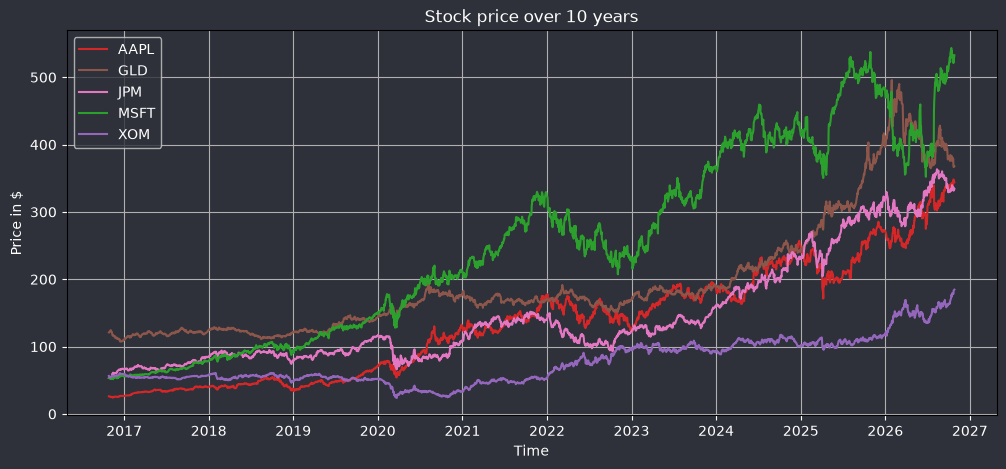

In [6]:
# graphing the different assets prices

color = ["tab:red", "tab:brown", "tab:pink", "tab:green", "tab:purple"]
i = 0
plt.figure(figsize=[12,5])
plt.title("Stock price over 10 years", color = "white")

for stock in df_us_stock_log_returns.ticker.unique():
    
    mask = (df_us_stock_log_returns.ticker == stock)

    plt.plot(df_us_stock_log_returns.date.loc[mask], df_us_stock_log_returns.close.loc[mask], label = stock, color = color[i])
    plt.xlabel("Time")
    i+=1
plt.ylabel("Price in $")

bg_color = '#2e313a'

plt.rcParams.update({
    'figure.facecolor': bg_color,
    'axes.facecolor': bg_color,
    'text.color': '#ffffff',
    'axes.labelcolor': '#ffffff',
    'xtick.color': '#ffffff',
    'ytick.color': '#ffffff'
})
fig = plt.gcf()
fig.patch.set_facecolor(bg_color)

for ax in fig.get_axes():
    ax.set_facecolor(bg_color)
    ax.xaxis.label.set_color('#ffffff')
    ax.yaxis.label.set_color('#ffffff')
    ax.tick_params(axis='x', colors='#ffffff')
    ax.tick_params(axis='y', colors='#ffffff')
    
    for text in ax.texts:
        text.set_color('#ffffff')
plt.grid("major")
plt.legend()
plt.show()

In [7]:
log_aapl = np.array(df_us_stock_log_returns.log_return.loc[df_us_stock_log_returns.ticker == 'AAPL'].dropna())
log_gld = np.array(df_us_stock_log_returns.log_return.loc[df_us_stock_log_returns.ticker == 'GLD'].dropna())
log_jpm = np.array(df_us_stock_log_returns.log_return.loc[df_us_stock_log_returns.ticker == 'JPM'].dropna())
log_msft = np.array(df_us_stock_log_returns.log_return.loc[df_us_stock_log_returns.ticker == 'MSFT'].dropna())
log_xom = np.array(df_us_stock_log_returns.log_return.loc[df_us_stock_log_returns.ticker == 'XOM'].dropna())

log_returns = pd.DataFrame(np.array([log_aapl, log_gld, log_jpm, log_msft, log_xom]).T)

In [8]:
# our volatility model that returns the Cholesky factor, the predicted volatility (day + 1) and the fitted models

def GARCH(returns, n_assets):
    std_residuals = pd.DataFrame(index=returns.index)
    fitted_models = []
    next_day_volatility = np.ones(n_assets)

    for col in returns.columns:
        model = arch_model(returns[col] * 100, vol='Garch', p=1, q=1, dist='t')
        res = model.fit(disp='off')
    
        fitted_models.append(res)
    
        std_residuals[col] = res.std_resid
    
        # models tomorrow's volatility
        forecast = res.forecast(horizon=1)
        next_day_volatility[col] = np.sqrt(forecast.variance.values[-1, 0]) / 100

    # converts the dataframe to numpy matrix for the rank transformation
    garch_residuals = std_residuals.values

    u_data = np.zeros_like(garch_residuals)
    for i in range(n_assets):
        # rank transforms to uniform [0, 1] (probability space)
        u_data[:, i] = stats.rankdata(garch_residuals[:, i]) / (len(garch_residuals) + 1)

    # converts uniform variables to standard normal space to estimate correlation matrix
    z_norm = stats.norm.ppf(u_data)
    CORRELATION = np.corrcoef(z_norm, rowvar=False)
    L = np.linalg.cholesky(CORRELATION)
    return L, fitted_models, next_day_volatility

In [9]:
# Monte-Carlo simulation returns the price multipliers
def MC_step(Nbr_sim, L, fitted_models, next_day_volatility):
    
    z_uncorr = np.random.normal(size=(n_assets, Nbr_sim))
    # correlates shocks using the Cholesky factor L
    z_corr = np.matmul(L, z_uncorr)
    # transforms correlated normal shocks back to Uniform via Gaussian CDF
    u_sim = stats.norm.cdf(z_corr)

    # maps Uniform draws through fitted Student's t marginals
    simulated_residuals = np.zeros((n_assets, Nbr_sim))
    for i in range(n_assets):
        nu = fitted_models[i].params['nu'] 
        simulated_residuals[i, :] = stats.t.ppf(u_sim[i, :], df=nu) * np.sqrt((nu - 2) / nu)
    # scales simulated residuals by tomorrow's GARCH forecasted volatility
    simulated_returns = simulated_residuals * next_day_volatility[:, None]

    # asset price multipliers for our 1-day forcast
    price_multipliers = np.exp(simulated_returns)

    return price_multipliers

In [10]:
Nbr_sim = 10000000
n_assets = 5

L, fitted_models, next_day_volatility = GARCH(log_returns, n_assets)
price_multipliers_garch = MC_step(Nbr_sim, L, fitted_models, next_day_volatility)
MC_raw_results = np.array(df_us_stock_log_returns.close)[-5:, None]*price_multipliers_garch

In [13]:
# sanity checks
CORRELATION = L @ L.T
MC_average_results = np.average(MC_raw_results, axis = 1)
print(f"Average simulated prices [AAPL, GLD, JPM, MSFT, XOM] : {MC_average_results}")

CORRELATION_MC = np.corrcoef(MC_raw_results)
print(f"Difference in correlations : \n{CORRELATION_MC - CORRELATION}")
print(f"Biggest difference : {round(np.abs(CORRELATION_MC - CORRELATION).max(),4)}")

Average simulated prices [AAPL, GLD, JPM, MSFT, XOM] : [343.93699517 367.85170536 334.06388359 532.65891173 184.56030817]
Difference in correlations : 
[[ 0.00000000e+00 -6.84520619e-04 -1.31177092e-02 -1.78011385e-02
  -5.27509844e-03]
 [-6.84520619e-04 -2.22044605e-16  1.27024249e-03 -1.34046009e-03
  -1.62781365e-03]
 [-1.31177092e-02  1.27024249e-03  1.11022302e-16 -1.08158524e-02
  -9.28057562e-03]
 [-1.78011385e-02 -1.34046009e-03 -1.08158524e-02  0.00000000e+00
  -2.65930785e-03]
 [-5.27509844e-03 -1.62781365e-03 -9.28057562e-03 -2.65930785e-03
   0.00000000e+00]]
Biggest difference : 0.0178


In [14]:
# "fat tail" parameter
print("ν parameters:")
print(f"AAPL:{fitted_models[0].params['nu']}")
print(f"GLD:{fitted_models[1].params['nu']}")
print(f"JPM:{fitted_models[2].params['nu']}")
print(f"MSFT:{fitted_models[3].params['nu']}")
print(f"XOM:{fitted_models[4].params['nu']}")

ν parameters:
AAPL:4.332500952137657
GLD:5.741273268564378
JPM:4.620501491750973
MSFT:4.806769309318998
XOM:7.826227296504786


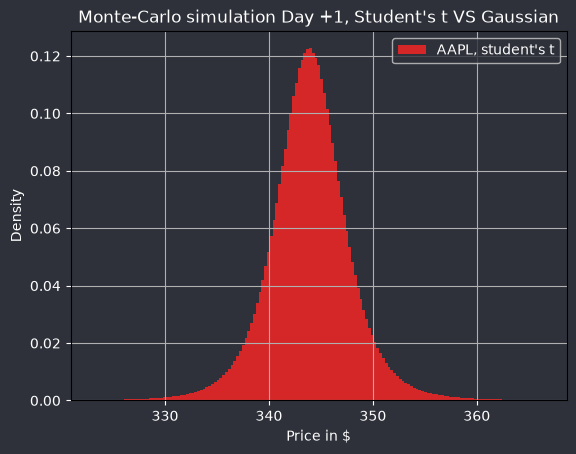

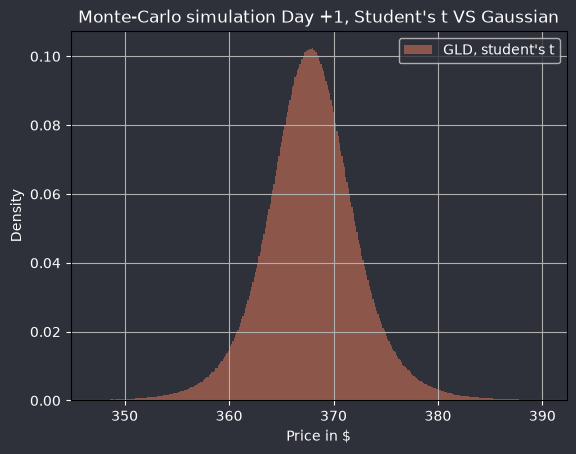

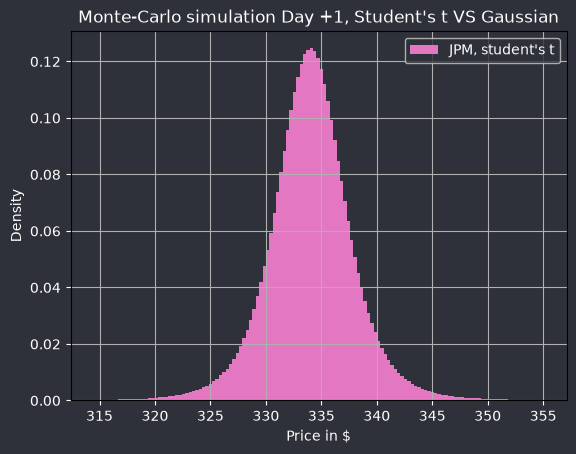

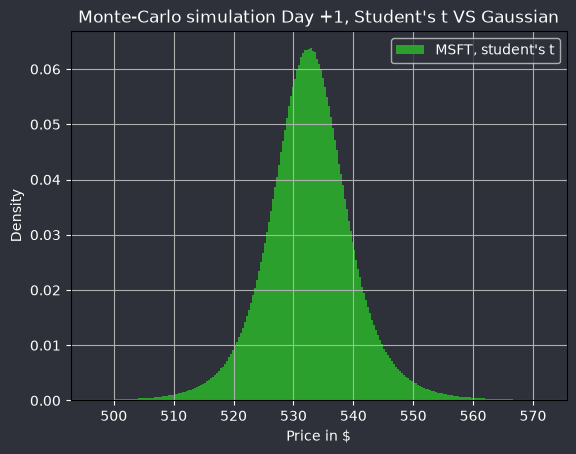

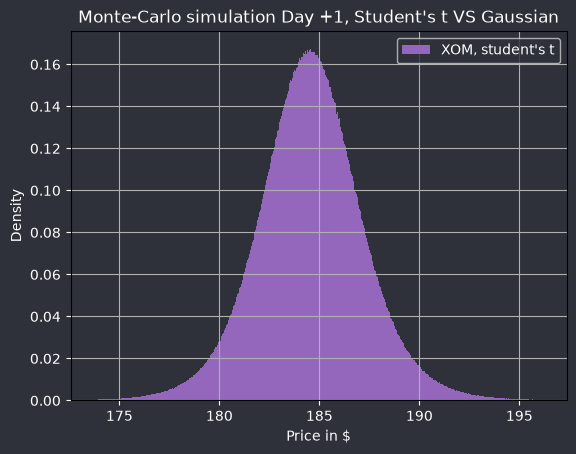

In [15]:
# graphing day + 1 prices from the Monte-Carlo simulations

ticker = ["AAPL", "GLD", "JPM", "MSFT", "XOM"]
color = ["tab:red", "tab:brown", "tab:pink", "tab:green", "tab:purple"]
for i in range(5):
    x_min = np.percentile(MC_raw_results[i,:], 0.1)
    x_max = np.percentile(MC_raw_results[i,:], 99.9)
    plt.figure()
    plt.title("Monte-Carlo simulation Day +1, Student's t VS Gaussian")
    plt.xlim([x_min-0.01*x_min,x_max+0.01*x_max])
    #plt.ylim([0,0.005])
    plt.hist(MC_raw_results[i,:], bins = 2000, density = True, label = f"{ticker[i]}, student's t", color = color[i])
    

    bg_color = '#2e313a'

    plt.rcParams.update({
    'figure.facecolor': bg_color,
    'axes.facecolor': bg_color,
    'text.color': '#ffffff',
    'axes.labelcolor': '#ffffff',
    'xtick.color': '#ffffff',
    'ytick.color': '#ffffff'
    })
    fig = plt.gcf()
    fig.patch.set_facecolor(bg_color)

    for ax in fig.get_axes():
        ax.set_facecolor(bg_color)
        ax.xaxis.label.set_color('#ffffff')
        ax.yaxis.label.set_color('#ffffff')
        ax.tick_params(axis='x', colors='#ffffff')
        ax.tick_params(axis='y', colors='#ffffff')
    
        for text in ax.texts:
            text.set_color('#ffffff')
    plt.xlabel("Price in $")
    plt.ylabel("Density")
    plt.grid("major")
    plt.legend()
    plt.show()

In [16]:
fund = 1000000
shares_ratio = np.array([0.2, 0.2, 0.2, 0.2, 0.2])
day_zero_value = np.zeros(5)
i = 0
for stock in ["AAPL", "GLD", "JPM", "MSFT", "XOM"]:
    day_zero_value[i] = df_us_stock_log_returns.loc[df_us_stock_log_returns.ticker == stock].close.iloc[-1]
    i+=1
portfolio_shares = shares_ratio*fund/day_zero_value
P_and_L_t = np.sum((MC_raw_results - np.array(day_zero_value[:,None]))*portfolio_shares[:,None], axis = 0)
var_99_t = -np.percentile(P_and_L_t, 1.0)
print(f"VaR Student-t 99% 1 day forecast: ${var_99_t:.2f}")
cvar_99_t = -np.mean(P_and_L_t[P_and_L_t <= -var_99_t])

print(f"CVaR Student-t 99% 1 day forecast: ${cvar_99_t:.2f}")

VaR Student-t 99% 1 day forecast: $18896.00
CVaR Student-t 99% 1 day forecast: $23262.42


In [17]:
def best_cvar(mc_shares_ratio):
    mc_var_99_t = np.percentile(np.sum((MC_raw_results - np.array(day_zero_value[:,None]))*(mc_shares_ratio*fund/day_zero_value)[:,None], axis = 0), 1.0)
    mc_portfolio_shares = mc_shares_ratio*fund/day_zero_value
    mc_P_and_L_t = np.sum((MC_raw_results - np.array(day_zero_value[:,None]))*mc_portfolio_shares[:,None], axis = 0)
    return -np.mean(mc_P_and_L_t[mc_P_and_L_t <= mc_var_99_t])

In [18]:
# starting guess
x0 = np.ones(n_assets) / n_assets

# hard constraint: sum(w) - 1 = 0
constraints = ({
    'type': 'eq',
    'fun': lambda w: np.sum(w) - 1.0
})

# bounds: each weight between 0% and 100% (long only)
bounds = tuple((0.0, 1.0) for _ in range(n_assets))

# run optimisation with SLSQP
res = minimize(
    fun=best_cvar,
    x0=x0,
    method='SLSQP',
    bounds=bounds,
    constraints=constraints,
    options={
        'eps' : 1e-5,
        'ftol': 1e-9,
        'maxiter': 1000,
        'disp': True
    }
)

print("Converged:", res.success)
print("Optimal Weights:", np.round(res.x, 4))
print("Sum of Weights:", np.sum(res.x))
print("Objective Value:", res.fun)

Optimization terminated successfully    (Exit mode 0)
            Current function value: 21677.2410347565
            Iterations: 15
            Function evaluations: 112
            Gradient evaluations: 15
Converged: True
Optimal Weights: [0.1751 0.3409 0.2094 0.0968 0.1779]
Sum of Weights: 1.0
Objective Value: 21677.2410347565


In [19]:
Optimised_portfolio_shares = res.x*fund/day_zero_value
Optimised_P_and_L_t = np.sum((MC_raw_results - np.array(day_zero_value[:,None]))*Optimised_portfolio_shares[:,None], axis = 0)

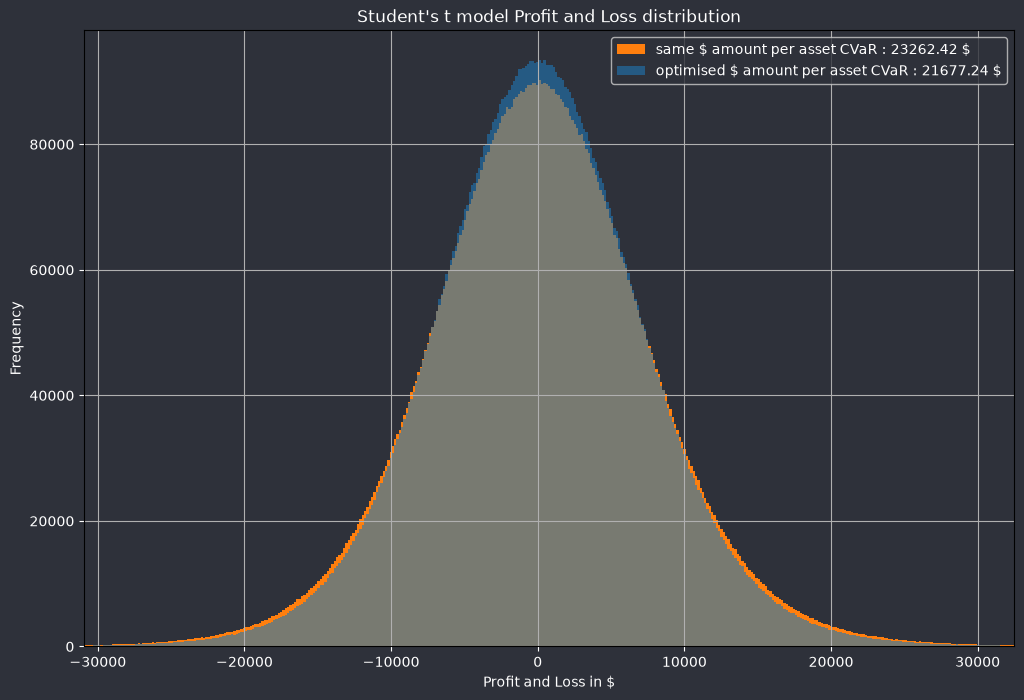

In [20]:
x_min = np.percentile(P_and_L_t, 0.1)
x_max = np.percentile(P_and_L_t, 99.9)
visible_min = x_min - 2000
visible_max = x_max + 2000
bins_zoomed = np.linspace(visible_min, visible_max, 400)
plt.figure(figsize = [12,8])
plt.title("Student's t model Profit and Loss distribution")
plt.xlim([x_min-2000,x_max+2000])
plt.hist(P_and_L_t, bins = bins_zoomed, density = False, label = f"same \$ amount per asset CVaR : {round(cvar_99_t,2)} \$", color = "tab:orange")
plt.hist(Optimised_P_and_L_t, bins = bins_zoomed, label = f"optimised \$ amount per asset CVaR : {round(res.fun,2)} \$", density = False, color = "tab:blue", alpha = 0.6)

bg_color = '#2e313a'

plt.rcParams.update({
    'figure.facecolor': bg_color,
    'axes.facecolor': bg_color,
    'text.color': '#ffffff',
    'axes.labelcolor': '#ffffff',
    'xtick.color': '#ffffff',
    'ytick.color': '#ffffff'
})
fig = plt.gcf()
fig.patch.set_facecolor(bg_color)

for ax in fig.get_axes():
    ax.set_facecolor(bg_color)
    ax.xaxis.label.set_color('#ffffff')
    ax.yaxis.label.set_color('#ffffff')
    ax.tick_params(axis='x', colors='#ffffff')
    ax.tick_params(axis='y', colors='#ffffff')
    
    for text in ax.texts:
        text.set_color('#ffffff')
plt.xlabel("Profit and Loss in $")
plt.ylabel("Frequency")
plt.legend()
plt.grid()
plt.show()

In [21]:
new_var_99_t = -np.percentile(Optimised_P_and_L_t, 1.0)
print(f"VaR Student-t 99% 1 day forecast: ${new_var_99_t:.2f}")
new_cvar_99_t = -np.mean(Optimised_P_and_L_t[Optimised_P_and_L_t <= -new_var_99_t])

print(f"CVaR Student-t 99% 1 day forecast: ${new_cvar_99_t:.2f}")

VaR Student-t 99% 1 day forecast: $17816.41
CVaR Student-t 99% 1 day forecast: $21677.24


## Backtesting

In [22]:
window_size = len(log_returns) - 1000  # last 1000 days for backtesting
backtest_results = []
weights = res.x
Nbr_sim = 1000000
for i in range(window_size, len(log_returns)):
    train_data = log_returns.iloc[:i]

    L, fitted_models, next_day_volatility = GARCH(train_data, n_assets)
    next_return = MC_step(Nbr_sim, L, fitted_models, next_day_volatility)

    shares_ratio = res.x

    var_99_t = np.percentile(np.dot(next_return.T - 1, shares_ratio), 1.0)
    
    simple_returns = np.expm1(log_returns.iloc[i])

    # applies weights via a dot product to get the true portfolio simple return
    actual_return = np.dot(simple_returns, weights)


    backtest_results.append({'date': log_returns.index[i], 'actual_portfolio_return': actual_return, 'predicted_var_99': var_99_t})

backtest_df = pd.DataFrame(backtest_results)

In [23]:
bad_days = backtest_df.loc[backtest_df.actual_portfolio_return < backtest_df.predicted_var_99]
bad_days

,date,actual_portfolio_return,predicted_var_99
32,1543,-0.023768,-0.020673
86,1597,-0.019118,-0.018813
363,1874,-0.019983,-0.016305
441,1952,-0.023589,-0.020396
461,1972,-0.015940,-0.015773
503,2014,-0.016515,-0.015684
536,2047,-0.023563,-0.015333
607,2118,-0.044476,-0.018521
608,2119,-0.052646,-0.030061
745,2256,-0.025025,-0.020821


Those two consecutive days should normally be looked at more closely to understand what is going on there.

In [24]:
n_bad_days = bad_days.date.count()
n_bad_days

np.int64(11)

We were theoretically supposed to get 10 days crossing the threshold. This is a good result.

## BigQuery Upload

In [ ]:
df_MC_raw_results = pd.DataFrame(MC_raw_results.T, columns = ["AAPL", "GLD", "JPM", "MSFT", "XOM"])

# upload to BigQuery and overwrite
dataset_id = "stock_prices_1"
table_id = f"{project_id}.{dataset_id}.mc_1_day_forecast"

job_config = bigquery.LoadJobConfig(
    write_disposition=bigquery.WriteDisposition.WRITE_TRUNCATE,
)

load_job = client.load_table_from_dataframe(
    df_MC_raw_results, 
    table_id, 
    job_config=job_config
)
load_job.result()

print("Table overwritten and loading done.")

print(f"Successfully loaded stock prices into BigQuery: {table_id}")

In [26]:
df_P_and_L = pd.DataFrame(np.concatenate((Optimised_P_and_L_t[:, None], P_and_L_t[:, None]), axis = 1), columns = ["Optimised_P_and_L_t","P_and_L_t"])
df_melted_P_and_L = pd.melt(df_P_and_L)


In [ ]:
df_P_and_L = pd.DataFrame(np.concatenate((Optimised_P_and_L_t[:, None], P_and_L_t[:, None]), axis = 1), columns = ["Optimised_P_and_L_t","P_and_L_t"])
df_melted_P_and_L = pd.melt(df_P_and_L)

# uploads to BigQuery and overwrites
dataset_id = "stock_prices_1"
table_id = f"{project_id}.{dataset_id}.mc_P_and_L_1_day_forecast"

job_config = bigquery.LoadJobConfig(
    write_disposition=bigquery.WriteDisposition.WRITE_TRUNCATE,
)

load_job = client.load_table_from_dataframe(
    df_melted_P_and_L, 
    table_id, 
    job_config=job_config
)
load_job.result()

print("Table overwritten and loading done.")

print(f"Successfully loaded stock prices into BigQuery: {table_id}")

In [ ]:
df_important_values = pd.DataFrame(np.array(([cvar_99_t], [new_cvar_99_t], [n_bad_days], [res.x[0]], [res.x[1]], [res.x[2]], [res.x[3]], [res.x[4]])).T, columns = ["cvar_99_t", "new_cvar_99_t", "n_bad_days", "ratio_AAPL", "ratio_GLD", "ratio_JPM", "ratio_MSFT", "ratio_XOM"])

# uploads to BigQuery and overwrites
dataset_id = "stock_prices_1"
table_id = f"{project_id}.{dataset_id}.important_values"

job_config = bigquery.LoadJobConfig(
    write_disposition=bigquery.WriteDisposition.WRITE_TRUNCATE,
)

load_job = client.load_table_from_dataframe(
    df_important_values, 
    table_id, 
    job_config=job_config
)
load_job.result()

print("Table overwritten and loading done.")

print(f"Successfully loaded stock prices into BigQuery: {table_id}")

Here is a link to a Google Data Studio Dashboard : https://datastudio.google.com/s/kQ4lT3ruJ00